# Evaluación y selección de configuraciones de muestreo DDIM

**Objetivo específico 3:** Desarrollar un modelo de difusión condicionado por plano anatómico, tipo de tumor y máscara tumoral para generar imágenes sintéticas de resonancia magnética cerebral.

Se comparan ocho configuraciones de muestreo DDIM mediante controles exploratorios de calidad, distancias de Fréchet, segmentación externa e inspección visual. La selección utiliza el conjunto de validación y preserva el conjunto de prueba final.


## 1. Bibliotecas y configuración

Se importan las dependencias y se establecen las rutas, condiciones y parámetros del procedimiento de evaluación.


In [13]:
from pathlib import Path
from collections import Counter
import os, re, json, hashlib, math, time, gc, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from scipy import ndimage as ndi
from scipy.linalg import svdvals
from tqdm.auto import tqdm
from IPython.display import display

SEED = 20261107
rng_global = np.random.default_rng(SEED)
CONDITIONS = [f"{t}_{p}" for t in ("gl", "me", "pi") for p in ("ax", "co", "sa")]
CONFIGS = [
    (50, 0.0), (50, 0.2),
    (100, 0.0), (100, 0.2),
    (200, 0.0), (200, 0.2),
    (300, 0.0), (300, 0.2),
]
N_CONFIGS = len(CONFIGS)

def cfg_tag(steps, eta):
    return f"ddim_steps{int(steps)}_eta{float(eta):.1f}".replace(".","p")
CONFIG_TAGS = [cfg_tag(*x) for x in CONFIGS]
if len(set(CONFIG_TAGS)) != N_CONFIGS:
    raise ValueError("CONFIGS contiene configuraciones duplicadas")

def localizar_raiz_repositorio():
    """Localiza la raíz del repositorio a partir del directorio de ejecución."""
    directorio = Path.cwd().resolve()
    for candidato in (directorio, *directorio.parents):
        if (candidato / "notebooks" / "OE3").is_dir():
            return candidato
    raise FileNotFoundError(
        "No se encontró la raíz del repositorio. "
        "Ubicar el notebook en notebooks/OE3/ y ejecutarlo desde el repositorio."
    )


REPO_ROOT = localizar_raiz_repositorio()
REPO_RESULTS = REPO_ROOT / "results"
DATA_ROOT = REPO_ROOT / "data" / "BRISC2025" / "segmentation_task"
SPLIT_CSV = REPO_RESULTS / "OE2" / "particiones" / "brisc_test_validation_test_50_50.csv"
EXPERIMENT_DIR = REPO_RESULTS / "OE3" / "difusion_gaussiana_v3" / "snr5_W1,2,6"
GENERATION_ROOT = EXPERIMENT_DIR / "pruebas_muestreo_DDIM"
OUT = REPO_RESULTS / "OE3" / "evaluacion_seleccion_DDIM"
OE2_SYNTHETIC_MASK_DIR = (
    REPO_RESULTS / "OE2" / "bernoulli" / "final" / "roiOE1_peso10"
    / "mascaras_sinteticas_finales" / "suavizado200" / "aceptadas"
)
DIRS = {k:OUT/k for k in ["00_inventarios","01_controles","02_fid_validacion",
                             "03_fid_exploratorio_train","04_dice","05_comparacion","cache"]}
for p in DIRS.values(): p.mkdir(parents=True,exist_ok=True)

# Parámetros acordados
SIZE = 256
MASK_THRESHOLD = 127
EXPECTED_TRAIN, EXPECTED_VALIDATION = 3792, 420
EXPECTED_SYNTH_PER_CONFIG, EXPECTED_SYNTH_PER_CONDITION = 900, 100
EXPECTED_SYNTH_TOTAL = N_CONFIGS * EXPECTED_SYNTH_PER_CONFIG
N_FID_REPEATS = 1000  # FID principal: validación
N_FID_TRAIN_EXTRA_REPEATS = 200  # FID exploratorio: train (sin cambios)
QC_MIN_REAL_REFERENCE = 25
FID_BATCH_INCEPTION = 8   # 16 GB VRAM: ajustar a 4 si hiciera falta
FID_BATCH_DINO = 8

# Activación de bloques, sin afectar salidas anteriores:
RUN_QUALITY = True
RUN_FID_VALIDATION = True
RUN_FID_TRAIN_EXTRA = False  # Análisis exploratorio complementario opcional.
RUN_DICE = True
RUN_SEGFORMER = True
RUN_WELLSCAN = True
REQUIRE_BOTH_SEGMENTERS = True
PRIMARY_DICE_OE3 = "SegFormer_B5_BRISC"  # Único Dice que se informa en selección OE3
if RUN_DICE and REQUIRE_BOTH_SEGMENTERS and not (RUN_SEGFORMER and RUN_WELLSCAN):
    raise ValueError("REQUIRE_BOTH_SEGMENTERS=True exige activar SegFormer y WellScan")

# Controles candidatos AR y BE: límites estimados exclusivamente con BRISC train.
# AR (área relativa): componente principal de tamaño reducido, P1 inferior por plano.
# BE (brillo exterior): píxeles exteriores con intensidad >=22, P99 superior por tumor y plano.
QC_AR_LOWER = 0.01
QC_BE_UPPER = 0.99
QC_THRESHOLD_R = 15                   # R15: excluir fondo oscuro conectado al borde
QC_THRESHOLD_BE = 22                   # Intensidad mínima de brillo exterior
QC_REFERENCE_REGION = "C15"           # Mayor componente conexa de R15, no R15 completa
QC_PROTOCOL_TAG = "AR_C15_P01_BE_C15_I22_P99"
QC_PARAMETERS = {
    "version": "qc_AR_BE_20261109_v1",
    "indicators": ["AR", "BE"],
    "ar_low": QC_AR_LOWER,
    "be_high": QC_BE_UPPER,
    "region_threshold": QC_THRESHOLD_R,
    "be_brightness_threshold": QC_THRESHOLD_BE,
    "spatial_region": QC_REFERENCE_REGION,
    "ar_calibration": "plane -> global, minimum 25 real images per group",
    "be_calibration": "condition -> tumor -> global, minimum 25 real images per group",
    "selection_status": "exploratory; no automatic rejection",
}
# Todos los archivos y cachés AR/BE se guardan en "01_controles".
# La firma y el identificador de protocolo impiden reutilizar cachés incompatibles.
(DIRS["01_controles"] / "parametros_qc.json").write_text(
    json.dumps(QC_PARAMETERS, ensure_ascii=False, indent=2), encoding="utf8"
)
SEGMENTATION_THRESHOLDS = {"SegFormer_B5_BRISC":0.50,"WellScan_ResUNet":0.38}

try:
    import torch
    DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print("PyTorch:", torch.__version__, "| dispositivo:", DEVICE)
except ImportError as exc:
    raise ImportError("Falta PyTorch. Instalar una versión compatible con torchvision/CUDA.") from exc
print("Experimento:",EXPERIMENT_DIR)
print("Salidas:",OUT)
print(f"Configuraciones ({N_CONFIGS}):",CONFIG_TAGS)
print("Imágenes sintéticas previstas:", EXPECTED_SYNTH_TOTAL)


PyTorch: 2.11.0+cu128 | dispositivo: cuda
Experimento: K:\Tesis\Github\results\OE3\difusion_gaussiana_v3\snr5_W1,2,6
Salidas: K:\Tesis\Github\results\OE3\evaluacion_seleccion_DDIM
Configuraciones (8): ['ddim_steps50_eta0p0', 'ddim_steps50_eta0p2', 'ddim_steps100_eta0p0', 'ddim_steps100_eta0p2', 'ddim_steps200_eta0p0', 'ddim_steps200_eta0p2', 'ddim_steps300_eta0p0', 'ddim_steps300_eta0p2']
Imágenes sintéticas previstas: 7200


## 2. Inventario de imágenes reales y sintéticas

Se indexan los pares de BRISC y las imágenes generadas, y se verifica su correspondencia entre configuraciones.


In [14]:
BRISC_RE = re.compile(r"^brisc2025_(train|test)_\d+_(gl|me|pi)_(ax|co|sa)_t1$",re.I)
COND_RE = re.compile(r"^(gl|me|pi)_(ax|co|sa)$",re.I)
IMAGE_EXTS = {".jpg",".jpeg",".png"}

def save_csv(df, path):
    path = Path(path); path.parent.mkdir(parents=True,exist_ok=True)
    tmp = path.with_name(path.name+".tmp")
    df.to_csv(tmp,index=False,encoding="utf-8-sig")
    os.replace(tmp,path)

def read_gray(path, size=SIZE):
    with Image.open(path) as im:
        im=im.convert("L")
        if im.size != (size,size):
            im=im.resize((size,size),Image.Resampling.BILINEAR)
        return np.asarray(im,dtype=np.uint8)

def read_mask(path, size=SIZE):
    with Image.open(path) as im:
        im=im.convert("L")
        if im.size != (size,size):
            im=im.resize((size,size),Image.Resampling.NEAREST)
        return np.asarray(im,dtype=np.uint8) > MASK_THRESHOLD

def index_real(split):
    if split not in {"train","validation"}:
        raise ValueError("Solo se permiten train/validation en selección DDIM; test_final está protegido.")
    if split == "validation":
        if not SPLIT_CSV.is_file(): raise FileNotFoundError(f"Split compartido inexistente: {SPLIT_CSV}")
        assignment = pd.read_csv(SPLIT_CSV,keep_default_na=False)
        if not {"basename","split"}.issubset(assignment.columns):
            raise ValueError("El split debe contener basename y split.")
        if assignment["basename"].duplicated().any():
            raise RuntimeError("Hay identificadores repetidos en el split.")
        allowed = set(assignment.loc[assignment["split"]=="validation","basename"].str.lower())
        root = DATA_ROOT / "test"
    else:
        allowed = None
        root = DATA_ROOT / "train"
    img_dir, mask_dir = root/"images", root/"masks"
    if not img_dir.is_dir() or not mask_dir.is_dir():
        raise FileNotFoundError(f"No existe {img_dir} o {mask_dir}")
    rows=[]
    for p in sorted(img_dir.iterdir()):
        if p.suffix.lower() not in IMAGE_EXTS:continue
        mat=BRISC_RE.fullmatch(p.stem)
        if mat is None:continue
        if allowed is not None and p.stem.lower() not in allowed:continue
        m = mask_dir/(p.stem+".png")
        if not m.is_file():raise FileNotFoundError(f"Máscara BRISC inexistente: {m}")
        _,tumor,plane=mat.groups(); cond=tumor.lower()+"_"+plane.lower()
        rows.append(dict(case_key=p.stem.lower(),condition=cond,tumor_code=tumor.lower(),
                         plane_code=plane.lower(),image_path=str(p),mask_path=str(m),
                         dataset="real_"+split))
    df=pd.DataFrame(rows)
    if df.empty:raise RuntimeError(f"BRISC {split} no contiene pares disponibles")
    if df.case_key.duplicated().any():raise RuntimeError("Duplicados BRISC en inventario")
    if split=="validation" and len(df)!=EXPECTED_VALIDATION:
        raise RuntimeError(f"Validación contiene {len(df)} y no {EXPECTED_VALIDATION}. Revisar split.")
    if split=="train" and len(df)!=EXPECTED_TRAIN:
        raise RuntimeError(f"Train contiene {len(df)} y no {EXPECTED_TRAIN}. Revisar dataset depurado.")
    return df.reset_index(drop=True)

def index_synthetic():
    frames=[]; issues=[]
    for steps,eta in CONFIGS:
        tag=cfg_tag(steps,eta)
        folder = GENERATION_ROOT/tag
        meta=folder/"synthetic_pairs_metadata.csv"
        if not meta.is_file():raise FileNotFoundError(f"No existe metadato de {tag}: {meta}")
        raw=pd.read_csv(meta,keep_default_na=False)
        required={"stem","condition_dir","image_path","mask_path","sample_seed",
                  "checkpoint_sha256","ddim_steps","ddim_eta"}
        missing=required-set(raw.columns)
        if missing:raise RuntimeError(f"{tag}: faltan campos: {sorted(missing)}")
        if len(raw)!=EXPECTED_SYNTH_PER_CONFIG:
            raise RuntimeError(f"{tag}: se esperaban {EXPECTED_SYNTH_PER_CONFIG} filas, encontradas {len(raw)}. Completar generación.")
        for r in raw.itertuples(index=False):
            cond=str(r.condition_dir).lower()
            if cond not in CONDITIONS:raise RuntimeError(f"{tag}: condición inválida {cond}")
            stem=str(r.stem)
            # Preferir la jerarquía REAL de V3, incluso si el CSV se movió de carpeta.
            p_img=folder/cond/(stem+"_oe3.png")
            if not p_img.exists():
                alternative=Path(str(r.image_path))
                if alternative.exists():p_img=alternative
            # Reconstrucción de la ruta actual de OE2 a partir de condición y archivo.
            p_mask = OE2_SYNTHETIC_MASK_DIR / cond / Path(str(r.mask_path)).name
            if not p_mask.is_file() and Path(str(r.mask_path)).is_file():
                p_mask = Path(str(r.mask_path))
            if not p_img.is_file() or not p_mask.is_file():
                issues.append(dict(config=tag,stem=stem,image=str(p_img),mask=str(p_mask)))
                continue
            rows=dict(config=tag,steps=int(steps),eta=float(eta),
                      case_key=cond+"/"+stem, stem=stem, condition=cond,
                      tumor_code=cond[:2],plane_code=cond[-2:],
                      image_path=str(p_img),mask_path=str(p_mask),
                      sample_seed=str(r.sample_seed),checkpoint_sha256=str(r.checkpoint_sha256),
                      dataset="sintetico")
            if int(r.ddim_steps)!=int(steps) or not np.isclose(float(r.ddim_eta),float(eta)):
                raise RuntimeError(f"Metadatos DDIM incompatibles con carpeta {tag}")
            frames.append(rows)
    if issues:
        save_csv(pd.DataFrame(issues),DIRS["00_inventarios"]/"archivos_ausentes.csv")
        raise FileNotFoundError(f"Faltan {len(issues)} pares V3. Ver archivos_ausentes.csv")
    out=pd.DataFrame(frames)
    counts=out.groupby(["config","condition"]).size().unstack(fill_value=0).reindex(index=CONFIG_TAGS,columns=CONDITIONS)
    if counts.isna().any().any() or not (counts==EXPECTED_SYNTH_PER_CONDITION).all().all():
        raise RuntimeError(f"No hay {EXPECTED_SYNTH_PER_CONDITION} imágenes por condición en cada configuración:\n{counts}")
    if out.duplicated(["config","case_key"]).any():raise RuntimeError("IDs sintéticos duplicados")
    base=set(out.loc[out.config==CONFIG_TAGS[0],"case_key"])
    for config,g in out.groupby("config"):
        if set(g.case_key)!=base: raise RuntimeError(f"No coinciden los {EXPECTED_SYNTH_PER_CONFIG} IDs de máscaras en {config}")
    # Verificar máscara, semillas iniciales y checkpoint compartidos por todas las configuraciones.
    if (out.groupby("case_key").mask_path.nunique()!=1).any():
        raise RuntimeError("Una misma clave utiliza máscaras diferentes entre configuraciones")
    if (out.groupby("case_key").sample_seed.nunique()!=1).any():
        raise RuntimeError("Las semillas iniciales no coinciden entre configuraciones")
    if out.checkpoint_sha256.nunique()!=1:
        raise RuntimeError("Se han mezclado checkpoints V3: no es comparable el procedimiento DDIM")
    return out.sort_values(["config","condition","case_key"]).reset_index(drop=True)

real_train=index_real("train")
real_val=index_real("validation")
syn=index_synthetic()
for name,frame in [("brisc_train",real_train),("brisc_validation",real_val),(f"sinteticas_{N_CONFIGS}_configuraciones",syn)]:
    save_csv(frame,DIRS["00_inventarios"]/(name+".csv"))
if len(syn) != EXPECTED_SYNTH_TOTAL:
    raise RuntimeError(f"Se esperaban {EXPECTED_SYNTH_TOTAL} sintéticas; se indexaron {len(syn)}")
print("Reales train:",len(real_train),"| reales validation:",len(real_val),"| sintéticas:",len(syn))
print("Checkpoint SHA256 de la generación:",syn.checkpoint_sha256.iloc[0])
display(real_val.groupby("condition").size().reindex(CONDITIONS).rename("n_validacion").to_frame())
display(syn.groupby("config").size().reindex(CONFIG_TAGS).rename("n_sinteticas").to_frame())


Reales train: 3792 | reales validation: 420 | sintéticas: 7200
Checkpoint SHA256 de la generación: c623672287d140889b2e7741c009f099ed31260a62752c96d7a74249e973bd76


,n_validacion
condition,
gl_ax,42
gl_co,40
gl_sa,44
me_ax,62
me_co,40
me_sa,42
pi_ax,62
pi_co,45
pi_sa,43


,n_sinteticas
config,
ddim_steps50_eta0p0,900
ddim_steps50_eta0p2,900
ddim_steps100_eta0p0,900
ddim_steps100_eta0p2,900
ddim_steps200_eta0p0,900
ddim_steps200_eta0p2,900
ddim_steps300_eta0p0,900
ddim_steps300_eta0p2,900


## 3. Controles exploratorios de calidad técnica

Se calculan indicadores de área relativa y brillo exterior con límites calibrados a partir de imágenes reales de entrenamiento.


In [15]:
EIGHT = ndi.generate_binary_structure(2, 2)

def border_connected_low(gray, threshold):
    low = gray <= threshold
    labels, n = ndi.label(low, structure=EIGHT)
    edge_labels = np.unique(np.concatenate([labels[0], labels[-1], labels[:, 0], labels[:, -1]]))
    edge_labels = edge_labels[edge_labels > 0]
    return np.isin(labels, edge_labels)

def largest_component(mask):
    labels, n = ndi.label(mask, structure=EIGHT)
    if n == 0:
        return np.zeros_like(mask, dtype=bool)
    sizes = np.bincount(labels.ravel())
    sizes[0] = 0
    return labels == int(np.argmax(sizes))

def extract_qc_features(gray):
    gray = np.asarray(gray, dtype=np.uint8)
    if gray.shape != (SIZE, SIZE):
        raise ValueError(f"Tamaño incorrecto {gray.shape}")

    # Región efectiva R15 y su componente principal C15 (no son lo mismo).
    region_R15 = ~border_connected_low(gray, QC_THRESHOLD_R)
    core15 = largest_component(region_R15)

    # AR (área relativa): fracción de píxeles ocupados por C15.
    AR = float(core15.mean())

    # BE (brillo exterior): fracción exterior de C15 con intensidad >=22, SIN distancia mínima.
    exterior = ~core15
    n_exterior = int(exterior.sum())
    bright_external = exterior & (gray >= QC_THRESHOLD_BE)
    BE = float(bright_external.sum() / max(n_exterior, 1))

    return {"AR": AR, "BE": BE}

def cache_signature(paths):
    h = hashlib.sha256()
    for path in paths:
        p = Path(path)
        s = p.stat()
        h.update(f"{p}|{s.st_size}|{s.st_mtime_ns}\n".encode("utf8"))
    return h.hexdigest()

def features_qc_cached(frame, cache_name):
    frame = frame.reset_index(drop=True)
    dest = DIRS["01_controles"] / ("qc_" + QC_PROTOCOL_TAG + "_" + cache_name + ".csv")
    sigfile = dest.with_suffix(".sig")
    # Impedir reutilización de resultados de protocolos QC anteriores.
    protocol_json = json.dumps(QC_PARAMETERS, sort_keys=True, ensure_ascii=True)
    sig = hashlib.sha256(
        (cache_signature(frame.image_path) + "\n" + protocol_json).encode("utf8")
    ).hexdigest()
    if dest.exists() and sigfile.exists() and sigfile.read_text().strip() == sig:
        cached = pd.read_csv(dest)
        if (len(cached) == len(frame) and
                {"AR", "BE"}.issubset(cached.columns) and
                cached.case_key.astype(str).tolist() == frame.case_key.astype(str).tolist()):
            return cached
    records = []
    for r in tqdm(frame.itertuples(index=False), total=len(frame), desc="QC " + cache_name):
        feat = extract_qc_features(read_gray(r.image_path))
        records.append({**r._asdict(), **feat})
    result = pd.DataFrame(records)
    if not np.isfinite(result[["AR", "BE"]].to_numpy(dtype=float)).all():
        raise RuntimeError("Características QC no finitas; comprobar PNG y regiones de interés")
    save_csv(result, dest)
    sigfile.write_text(sig, encoding="utf8")
    return result

if RUN_QUALITY:
    qc_train = features_qc_cached(real_train, "train")
    qc_val = features_qc_cached(real_val, "validacion")
    qc_syn = features_qc_cached(syn, "sinteticas")
    print("Características AR/BE extraídas:", len(qc_train), len(qc_val), len(qc_syn))


Características AR/BE extraídas: 3792 420 7200


In [16]:
if RUN_QUALITY:
    QC_KEYS = ["AR", "BE"]

    def estimate_limits(ref, min_n=QC_MIN_REAL_REFERENCE):
        rows = []
        def add(group_type, group_key, data, feature, quantile):
            v = pd.to_numeric(data[feature], errors="coerce").to_numpy(dtype=float)
            v = v[np.isfinite(v)]
            if len(v) < min_n:
                return
            rows.append({
                "group_type": group_type, "group_key": str(group_key),
                "feature": feature, "limit": float(np.quantile(v, quantile)), "n": len(v)
            })

        # AR: solo calibración por plano y respaldo global.
        add("global", "global", ref, "AR", QC_AR_LOWER)
        for plane, group in ref.groupby("plane_code"):
            add("plane", plane, group, "AR", QC_AR_LOWER)

        # BE: calibración por condición tumor-plano, respaldo por tumor y global.
        add("global", "global", ref, "BE", QC_BE_UPPER)
        for tumor, group in ref.groupby("tumor_code"):
            add("tumor", tumor, group, "BE", QC_BE_UPPER)
        for condition, group in ref.groupby("condition"):
            add("condition", condition, group, "BE", QC_BE_UPPER)
        return pd.DataFrame(rows)

    qc_limits = estimate_limits(qc_train)
    if qc_limits.empty or set(qc_limits.feature) != set(QC_KEYS):
        raise RuntimeError("No se pudieron estimar límites QC de referencia")
    save_csv(qc_limits, DIRS["01_controles"] / "limites_referencia_BRISC_train.csv")
    limits_index = {(r.group_type, r.group_key, r.feature): (r.limit, r.n)
                    for r in qc_limits.itertuples(index=False)}

    def apply_limits(table):
        out = table.reset_index(drop=True).copy()
        out["AR_bajo"] = False
        out["BE_alto"] = False
        out["AR_grupo_referencia"] = ""
        out["BE_grupo_referencia"] = ""
        out["AR_lim_inf"] = np.nan
        out["BE_lim_sup"] = np.nan

        for i, r in enumerate(out.itertuples(index=False)):
            # AR NO se calibra por tumor: siempre por plano si hay >=25 casos.
            ar_levels = [("plane", r.plane_code), ("global", "global")]
            ar_level = next((key for key in ar_levels if (*key, "AR") in limits_index), None)
            if ar_level is None:
                raise RuntimeError(f"Sin límite AR para el plano {r.plane_code}")
            ar_limit, _ = limits_index[(*ar_level, "AR")]
            out.at[i, "AR_grupo_referencia"] = f"{ar_level[0]}:{ar_level[1]}"
            out.at[i, "AR_lim_inf"] = ar_limit
            out.at[i, "AR_bajo"] = bool(float(r.AR) < ar_limit)

            be_levels = [("condition", r.condition), ("tumor", r.tumor_code),
                        ("global", "global")]
            be_level = next((key for key in be_levels if (*key, "BE") in limits_index), None)
            if be_level is None:
                raise RuntimeError(f"Sin límite BE para la condición {r.condition}")
            be_limit, _ = limits_index[(*be_level, "BE")]
            out.at[i, "BE_grupo_referencia"] = f"{be_level[0]}:{be_level[1]}"
            out.at[i, "BE_lim_sup"] = be_limit
            out.at[i, "BE_alto"] = bool(float(r.BE) > be_limit)

        out["alguna_alerta"] = out["AR_bajo"] | out["BE_alto"]
        out["cantidad_alertas"] = out[["AR_bajo", "BE_alto"]].sum(axis=1)
        return out

    qc_train_flags = apply_limits(qc_train)
    qc_syn = apply_limits(qc_syn)
    qc_val = apply_limits(qc_val)
    flags = ["AR_bajo", "BE_alto", "alguna_alerta"]

    def qc_table(df, keys):
        # La columna alguna_alerta es la unión de imágenes, sin doble conteo.
        tab = df.groupby(keys, sort=False).agg(
            n=("case_key", "size"), **{c: (c, "sum") for c in flags}
        ).reset_index()
        for c in flags:
            tab[c + "_pct"] = (100 * tab[c] / tab.n).round(2)
        return tab

    qc_overall = qc_table(qc_syn, ["config"])
    qc_detail = qc_table(qc_syn, ["config", "condition"])
    qc_overall = qc_overall.set_index("config").reindex(CONFIG_TAGS).reset_index()
    qc_detail["condition"] = pd.Categorical(qc_detail.condition, categories=CONDITIONS, ordered=True)
    qc_detail = qc_detail.sort_values(["config", "condition"])
    qc_real_reference = qc_table(qc_val, ["condition"])
    qc_train_reference = qc_table(qc_train_flags, ["dataset"])

    save_csv(qc_train_reference, DIRS["01_controles"] / "qc_train_autocalibracion.csv")
    save_csv(qc_syn, DIRS["01_controles"] / "qc_individual_todas_las_imagenes.csv")
    save_csv(qc_val, DIRS["01_controles"] / "qc_validacion_referencia.csv")
    save_csv(qc_overall, DIRS["01_controles"] / "qc_resumen_por_configuracion.csv")
    save_csv(qc_detail, DIRS["01_controles"] / "qc_por_configuracion_y_condicion.csv")
    save_csv(qc_real_reference, DIRS["01_controles"] / "qc_validacion_por_condicion.csv")

    print("TABLA RESUMEN — CONTEOS Y PORCENTAJES DE ALERTAS")
    display(qc_overall[["config", "n"] + flags + [c + "_pct" for c in flags]])
    print("TABLA POR CONDICIÓN — CONTEOS Y PORCENTAJES")
    display(qc_detail[["config", "condition", "n"] + flags + [c + "_pct" for c in flags]])
    print("CONTROL TRAIN — verificación descriptiva de calibración")
    display(qc_train_reference[["dataset", "n"] + flags + [c + "_pct" for c in flags]])
    print("Límites: AR < P1 por plano; BE > P99 por condición tumor-plano.")


TABLA RESUMEN — CONTEOS Y PORCENTAJES DE ALERTAS


,config,n,AR_bajo,BE_alto,alguna_alerta,AR_bajo_pct,BE_alto_pct,alguna_alerta_pct
0,ddim_steps50_eta0p0,900,0,25,25,0.0,2.78,2.78
1,ddim_steps50_eta0p2,900,0,20,20,0.0,2.22,2.22
2,ddim_steps100_eta0p0,900,0,18,18,0.0,2.00,2.00
3,ddim_steps100_eta0p2,900,0,16,16,0.0,1.78,1.78
4,ddim_steps200_eta0p0,900,0,19,19,0.0,2.11,2.11
5,ddim_steps200_eta0p2,900,0,16,16,0.0,1.78,1.78
6,ddim_steps300_eta0p0,900,0,19,19,0.0,2.11,2.11
7,ddim_steps300_eta0p2,900,0,15,15,0.0,1.67,1.67


TABLA POR CONDICIÓN — CONTEOS Y PORCENTAJES


,config,condition,n,AR_bajo,BE_alto,alguna_alerta,AR_bajo_pct,BE_alto_pct,alguna_alerta_pct
0,ddim_steps100_eta0p0,gl_ax,100,0,4,4,0.0,4.0,4.0
1,ddim_steps100_eta0p0,gl_co,100,0,0,0,0.0,0.0,0.0
2,ddim_steps100_eta0p0,gl_sa,100,0,3,3,0.0,3.0,3.0
3,ddim_steps100_eta0p0,me_ax,100,0,0,0,0.0,0.0,0.0
4,ddim_steps100_eta0p0,me_co,100,0,2,2,0.0,2.0,2.0
...,...,...,...,...,...,...,...,...,...
67,ddim_steps50_eta0p2,me_co,100,0,3,3,0.0,3.0,3.0
68,ddim_steps50_eta0p2,me_sa,100,0,0,0,0.0,0.0,0.0
69,ddim_steps50_eta0p2,pi_ax,100,0,8,8,0.0,8.0,8.0
70,ddim_steps50_eta0p2,pi_co,100,0,1,1,0.0,1.0,1.0


CONTROL TRAIN — verificación descriptiva de calibración


,dataset,n,AR_bajo,BE_alto,alguna_alerta,AR_bajo_pct,BE_alto_pct,alguna_alerta_pct
0,real_train,3792,39,43,82,1.03,1.13,2.16


Límites: AR < P1 por plano; BE > P99 por condición tumor-plano.


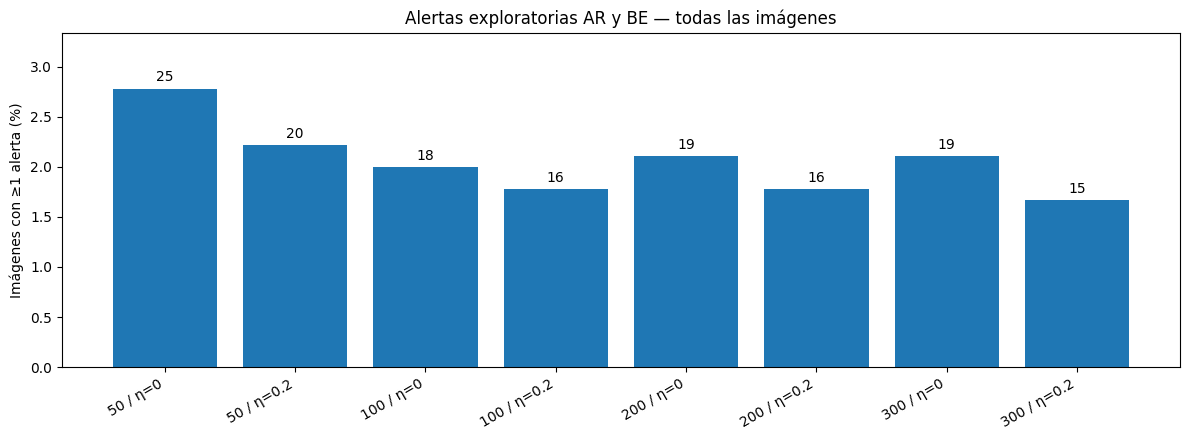

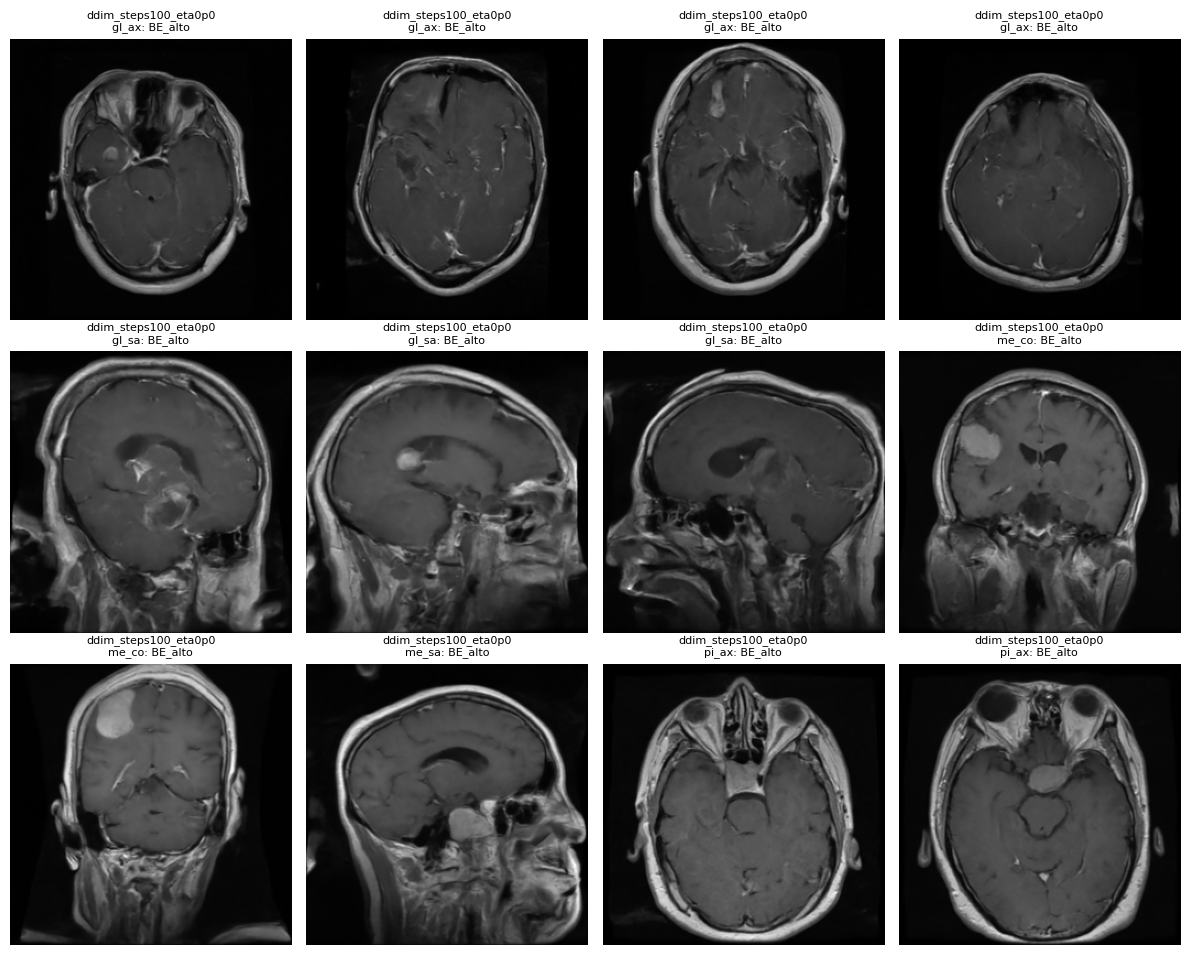

In [17]:
if RUN_QUALITY:
    fig,ax=plt.subplots(figsize=(max(11, 1.5*N_CONFIGS),4.5))
    order=qc_overall.set_index("config").loc[CONFIG_TAGS]
    barras = ax.bar(np.arange(N_CONFIGS), order["alguna_alerta_pct"].to_numpy())
    # La altura indica el porcentaje; la etiqueta es el número absoluto de imágenes con alerta.
    ax.bar_label(
        barras,
        labels=[str(int(n)) for n in order["alguna_alerta"].to_numpy()],
        padding=3,
        fontsize=10,
    )
    ax.set_ylim(0, max(1, float(order["alguna_alerta_pct"].max()) * 1.20))
    ax.set_xticks(np.arange(N_CONFIGS),[f"{s} / η={e:g}" for s,e in CONFIGS],rotation=30,ha="right")
    ax.set_ylabel("Imágenes con ≥1 alerta (%)")
    ax.set_title("Alertas exploratorias AR y BE — todas las imágenes")
    fig.tight_layout()
    fig.savefig(DIRS["01_controles"]/"tasa_alertas_por_configuracion.png",dpi=180)
    plt.show()
    # Figura diagnóstica de alarmas individuales; NO cambia las muestras evaluadas en otras secciones.
    bad=qc_syn.loc[qc_syn.alguna_alerta].sort_values(["cantidad_alertas","config"],ascending=[False,True]).head(12)
    if not bad.empty:
        ncol=4; nrow=math.ceil(len(bad)/ncol)
        fig,ax=plt.subplots(nrow,ncol,figsize=(12,3.2*nrow),squeeze=False)
        for axis in ax.ravel():axis.axis("off")
        for axis,r in zip(ax.ravel(),bad.itertuples(index=False)):
            axis.imshow(read_gray(r.image_path),cmap="gray",vmin=0,vmax=255)
            triggered=[x for x in flags[:-1] if getattr(r,x)]
            axis.set_title(f"{r.config}\n{r.condition}: {','.join(triggered)}",fontsize=8)
        fig.tight_layout()
        fig.savefig(DIRS["01_controles"]/"ejemplos_alertas.png",dpi=140)
        plt.show()

## 4. Extracción de características y distancia de Fréchet

Se implementa el cálculo de la distancia entre distribuciones de características extraídas mediante InceptionV3 y DINOv2.


In [18]:
def frechet_factorized(x, y, prefer_cuda=True):
    """Distancia de Fréchet entre Gaussianas empíricas, covarianza muestral (n-1).

    Tr[(SigmaX^{1/2} SigmaY SigmaX^{1/2})^{1/2}] =
    ||(X_c/sqrt(n-1)) @ (Y_c/sqrt(m-1)).T||_* (norma nuclear).
    X e Y: muestras en filas, características en columnas.
    """
    x=np.asarray(x,dtype=np.float64);y=np.asarray(y,dtype=np.float64)
    if x.ndim!=2 or y.ndim!=2 or x.shape[1]!=y.shape[1] or min(len(x),len(y))<2:
        raise ValueError(f"Formas FID incompatibles: {x.shape} y {y.shape}")
    if not np.isfinite(x).all() or not np.isfinite(y).all():
        raise ValueError("FID no admite características no finitas")
    cx=x-x.mean(axis=0,keepdims=True);cy=y-y.mean(axis=0,keepdims=True)
    mean_term=float(np.sum((x.mean(axis=0)-y.mean(axis=0))**2))
    tx=float(np.sum(cx*cx)/(len(x)-1));ty=float(np.sum(cy*cy)/(len(y)-1))
    # Producto cruzado n × m; reduce sustancialmente el costo frente a 2048×2048.
    if prefer_cuda and torch.cuda.is_available():
        try:
            with torch.no_grad():
                xx=torch.as_tensor(cx,device="cuda",dtype=torch.float64)
                yy=torch.as_tensor(cy,device="cuda",dtype=torch.float64)
                cross=(xx @ yy.T)/math.sqrt((len(x)-1)*(len(y)-1))
                nuclear=float(torch.linalg.svdvals(cross).sum().cpu())
                del xx,yy,cross
        except RuntimeError as exc:
            warnings.warn(f"SVD CUDA falló; se usa SciPy CPU: {str(exc)[:140]}")
            cross=(cx @ cy.T)/math.sqrt((len(x)-1)*(len(y)-1))
            nuclear=float(svdvals(cross,check_finite=False).sum())
    else:
        cross=(cx @ cy.T)/math.sqrt((len(x)-1)*(len(y)-1))
        nuclear=float(svdvals(cross,check_finite=False).sum())
    d=mean_term+tx+ty-2*nuclear
    if d < -1e-5:raise ArithmeticError(f"FID negativo numéricamente significativo: {d}")
    return max(0.0,float(d))

# Prueba de consistencia matemática: Fréchet por raíz de covarianzas vs factorización.
from scipy.linalg import sqrtm
rg=np.random.default_rng(77)
a=rg.normal(size=(17,9));b=rg.normal(loc=.2,size=(13,9))
mu_a=a.mean(0);mu_b=b.mean(0)
ca=np.cov(a,rowvar=False);cb=np.cov(b,rowvar=False)
root=sqrtm(ca@cb)
reference=float(np.sum((mu_a-mu_b)**2)+np.trace(ca+cb-2*root).real)
assert np.isclose(frechet_factorized(a,b,prefer_cuda=False),reference,atol=1e-6,rtol=1e-6)
assert frechet_factorized(a,a,prefer_cuda=False)<1e-8
print("Pruebas numéricas FID: correctas")

Pruebas numéricas FID: correctas


In [19]:
from torch.utils.data import Dataset,DataLoader
class ImageDataset(Dataset):
    def __init__(self, paths):self.paths=list(map(str,paths))
    def __len__(self):return len(self.paths)
    def __getitem__(self,i):
        return Image.fromarray(read_gray(self.paths[i]),mode="L").convert("RGB")

def load_feature_model(name):
    if name=="InceptionV3":
        from pytorch_fid.inception import InceptionV3
        model=InceptionV3([InceptionV3.BLOCK_INDEX_BY_DIM[2048]],
                          resize_input=True,normalize_input=True,use_fid_inception=True)
        model.to(DEVICE).eval()
        return model,None
    if name=="DINOv2_S":
        from transformers import AutoImageProcessor,AutoModel
        repo="facebook/dinov2-small"
        processor=AutoImageProcessor.from_pretrained(repo,trust_remote_code=False)
        model=AutoModel.from_pretrained(repo,trust_remote_code=False).to(DEVICE).eval()
        return model,processor
    raise ValueError(name)

@torch.inference_mode()
def batch_feature_vectors(name,model,processor,pils):
    if name=="InceptionV3":
        tensor=torch.from_numpy(np.stack([np.asarray(im,dtype=np.float32)/255. for im in pils]))
        tensor=tensor.permute(0,3,1,2).to(DEVICE)
        feat=model(tensor)[0]
        return feat.flatten(start_dim=1).detach().cpu().numpy().astype(np.float32)
    values=processor(images=pils,return_tensors="pt")
    values={k:v.to(DEVICE) for k,v in values.items()}
    result=model(**values)
    return result.last_hidden_state[:,0,:].detach().cpu().numpy().astype(np.float32)

def feature_cache_path(extractor,dataset):
    return DIRS["cache"]/f"feature_{extractor}_{dataset}.npz"

def cached_feature_exists(extractor,dataset,frame):
    path=feature_cache_path(extractor,dataset)
    if not path.is_file():return False
    try:
        with np.load(path,allow_pickle=False) as arc:
            return (str(arc["signature"])==cache_signature(frame.image_path)
                    and np.array_equal(arc["keys"],frame.case_key.astype(str).to_numpy())
                    and len(arc["features"])==len(frame))
    except Exception:return False

def extract_features(extractor, frame, dataset, model, processor):
    path=feature_cache_path(extractor,dataset)
    if cached_feature_exists(extractor,dataset,frame):
        with np.load(path,allow_pickle=False) as arc:
            return arc["features"].copy()
    bs=FID_BATCH_INCEPTION if extractor=="InceptionV3" else FID_BATCH_DINO
    chunks=[]
    paths=frame.image_path.astype(str).tolist()
    for start in tqdm(range(0,len(paths),bs),desc=f"{extractor} {dataset}"):
        pels=[Image.fromarray(read_gray(q),mode="L").convert("RGB") for q in paths[start:start+bs]]
        f=batch_feature_vectors(extractor,model,processor,pels)
        chunks.append(f)
    features=np.vstack(chunks).astype(np.float32)
    expected_dim=2048 if extractor=="InceptionV3" else 384
    assert features.shape==(len(frame),expected_dim)
    np.savez_compressed(path,features=features,keys=np.asarray(frame.case_key.astype(str).tolist(),dtype="U"),
                        signature=cache_signature(paths),extractor=extractor)
    return features

FID_EXTRACTORS=["InceptionV3","DINOv2_S"]
# Función construida para entrenar/cargar SOLO un extractor a la vez (limita uso de VRAM).
def ensure_all_feature_caches(include_train=False):
    frames={"val":real_val,**{tag:syn.loc[syn.config==tag].reset_index(drop=True) for tag in CONFIG_TAGS}}
    if include_train: frames["train"]=real_train
    for extractor in FID_EXTRACTORS:
        needed=[(key,df) for key,df in frames.items() if not cached_feature_exists(extractor,key,df)]
        if not needed:
            print(extractor,": todas las características en caché")
            continue
        print(f"Cargando extractor {extractor} para {len(needed)} conjuntos")
        model,processor=load_feature_model(extractor)
        for key,df in needed:extract_features(extractor,df,key,model,processor)
        del model,processor
        gc.collect()
        if torch.cuda.is_available():torch.cuda.empty_cache()

if RUN_FID_VALIDATION or RUN_FID_TRAIN_EXTRA:
    ensure_all_feature_caches(include_train=RUN_FID_TRAIN_EXTRA)

InceptionV3 : todas las características en caché
DINOv2_S : todas las características en caché


## 5. Comparación de FID con validación

Se realizan 1000 remuestreos estratificados sin reemplazo, comparando 420 imágenes de validación con conjuntos sintéticos de igual composición.


In [8]:
def get_feature_matrix(extractor,source,frame):
    path=feature_cache_path(extractor,source)
    if not cached_feature_exists(extractor,source,frame):
        raise FileNotFoundError(f"Caché inválida/ausente: {path}. Ejecutar extracción.")
    with np.load(path,allow_pickle=False) as arc: return arc["features"].copy()

fid_val_repeticiones=pd.DataFrame()
if RUN_FID_VALIDATION:
    val_counts=real_val.groupby("condition").size().reindex(CONDITIONS,fill_value=0)
    if (val_counts<1).any():raise RuntimeError("Falta al menos una condición en validación")
    if (val_counts>100).any():
        raise RuntimeError(f"Hay estratos de validación >100: {val_counts[val_counts>100].to_dict()}")
    # Marco canónico de 900 casos (orden fijo) para emparejar configuraciones.
    base=syn.loc[syn.config==CONFIG_TAGS[0]].sort_values("case_key").reset_index(drop=True)
    ordered={tag:syn.loc[syn.config==tag].set_index("case_key").loc[base.case_key].reset_index()
             for tag in CONFIG_TAGS}
    f_syn={}
    f_val={}
    for extractor in FID_EXTRACTORS:
        f_val[extractor]=get_feature_matrix(extractor,"val",real_val)
        for tag in CONFIG_TAGS:
            source=syn.loc[syn.config==tag].reset_index(drop=True)
            matrix=get_feature_matrix(extractor,tag,source)
            mapping={key:i for i,key in enumerate(source.case_key)}
            f_syn[(extractor,tag)]=matrix[[mapping[key] for key in base.case_key]]
    rng=np.random.default_rng(SEED+11)
    draw_indices=[]
    for b in range(N_FID_REPEATS):
        pick=[]
        for cond in CONDITIONS:
            positions=np.flatnonzero(base.condition.to_numpy()==cond)
            pick.extend(rng.choice(positions,size=int(val_counts[cond]),replace=False).tolist())
        draw_indices.append(np.asarray(pick,dtype=int))
    pd.DataFrame([{"repeticion":b+1,"case_key":base.iloc[i].case_key}
                  for b,indices in enumerate(draw_indices) for i in indices]).to_csv(
                      DIRS["02_fid_validacion"]/f"selecciones_sinteticas_emparejadas_{N_FID_REPEATS}.csv",index=False)
    rows=[]
    fid_partial_path = DIRS["02_fid_validacion"]/f"FID_{N_FID_REPEATS}_repeticiones_parcial.csv"
    for extractor in FID_EXTRACTORS:
        for b,idx in enumerate(tqdm(draw_indices,desc=f"FID {extractor} validación"),start=1):
            for tag in CONFIG_TAGS:
                rows.append(dict(extractor=extractor,repeticion=b,config=tag,
                                 n_real=len(real_val),n_sintetica=len(idx),
                                 fid=frechet_factorized(f_val[extractor],f_syn[(extractor,tag)][idx])))
            # Punto de recuperación informativo cada 25 repeticiones (no se reutiliza
            # automáticamente: cada ejecución comienza íntegra para evitar mezclar corridas).
            if b % 25 == 0 or b == N_FID_REPEATS:
                save_csv(pd.DataFrame(rows),fid_partial_path)
    fid_val_repeticiones=pd.DataFrame(rows)
    save_csv(fid_val_repeticiones,DIRS["02_fid_validacion"]/f"fid_{N_FID_REPEATS}_repeticiones.csv")
    fid_val_resumen=fid_val_repeticiones.groupby(["extractor","config"],as_index=False).fid.agg(
        media="mean",de="std",p05=lambda x:np.quantile(x,.05),
        mediana="median",p95=lambda x:np.quantile(x,.95)).sort_values(["extractor","media"])
    # Porcentaje de veces que la configuración obtuvo el mínimo dentro de cada repetición.
    winners=fid_val_repeticiones.loc[fid_val_repeticiones.groupby(["extractor","repeticion"]).fid.idxmin()]
    counts=winners.groupby(["extractor","config"]).size().rename("n_veces_minimo").reset_index()
    fid_val_resumen=fid_val_resumen.merge(counts,on=["extractor","config"],how="left")
    fid_val_resumen["n_veces_minimo"]=fid_val_resumen.n_veces_minimo.fillna(0).astype(int)
    fid_val_resumen["pct_minimo"]=100*fid_val_resumen.n_veces_minimo/N_FID_REPEATS
    save_csv(fid_val_resumen,DIRS["02_fid_validacion"]/"fid_resumen_por_configuracion.csv")
    display(fid_val_resumen.round(4))

FID InceptionV3 validación:   0%|          | 0/1000 [00:00<?, ?it/s]

FID DINOv2_S validación:   0%|          | 0/1000 [00:00<?, ?it/s]

,extractor,config,media,de,p05,mediana,p95,n_veces_minimo,pct_minimo
0,DINOv2_S,ddim_steps300_eta0p2,192.7208,2.4765,188.6038,192.7074,196.7851,789,78.9
1,DINOv2_S,ddim_steps200_eta0p2,194.5505,2.5416,190.4872,194.4678,198.7378,77,7.7
2,DINOv2_S,ddim_steps300_eta0p0,195.6120,2.5796,191.1758,195.5517,199.9300,134,13.4
3,DINOv2_S,ddim_steps200_eta0p0,197.0271,2.6467,192.5180,196.9725,201.5065,0,0.0
4,DINOv2_S,ddim_steps100_eta0p2,200.2120,2.8393,195.5123,200.1501,204.8921,0,0.0
5,DINOv2_S,ddim_steps100_eta0p0,200.5719,2.7098,196.1096,200.5408,205.0463,0,0.0
6,DINOv2_S,ddim_steps50_eta0p2,209.6693,2.7935,205.1914,209.6462,214.1549,0,0.0
7,DINOv2_S,ddim_steps50_eta0p0,215.9170,2.8152,211.3208,215.9075,220.8466,0,0.0
8,InceptionV3,ddim_steps300_eta0p2,55.9252,0.5379,55.0911,55.9182,56.8510,902,90.2
9,InceptionV3,ddim_steps200_eta0p2,56.3891,0.5487,55.4684,56.3981,57.2530,65,6.5


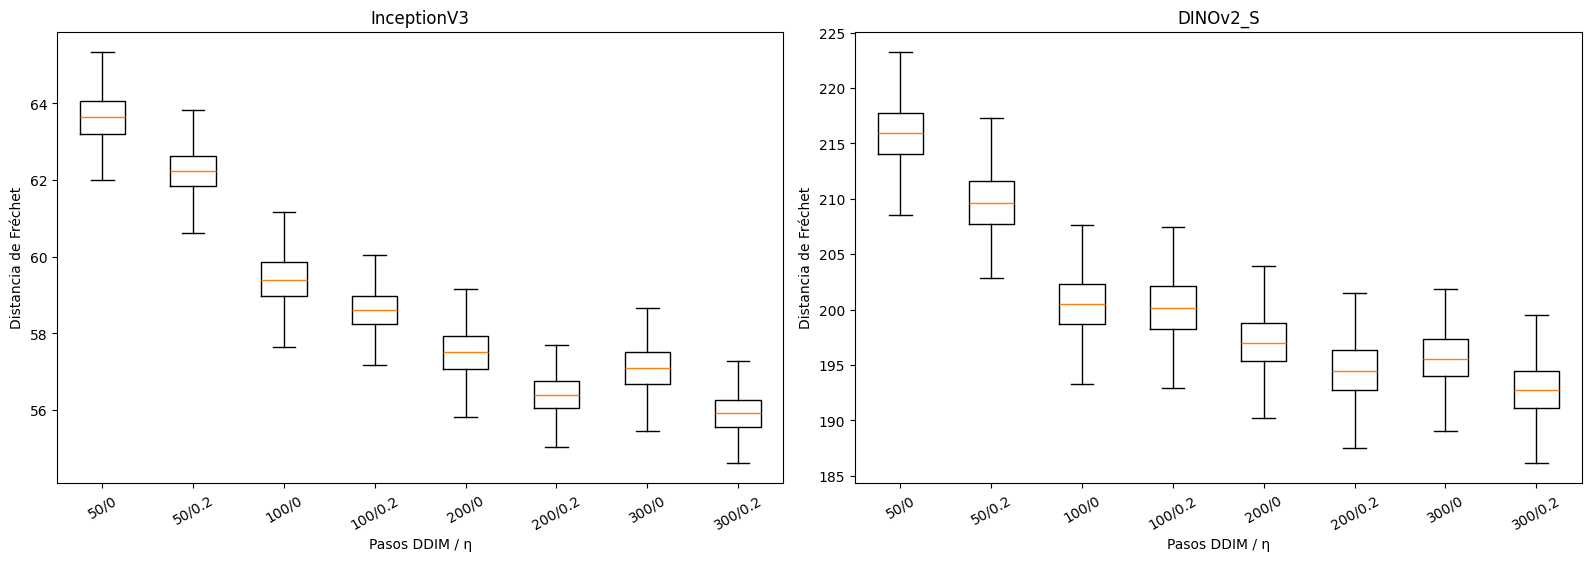

In [9]:
if RUN_FID_VALIDATION and not fid_val_repeticiones.empty:
    fig,axes=plt.subplots(1,2,figsize=(max(15, 1.1*N_CONFIGS + 7),5.5),layout="constrained")
    for ax,extr in zip(axes,FID_EXTRACTORS):
        data=[fid_val_repeticiones.query("extractor==@extr and config==@tag").fid.to_numpy()
              for tag in CONFIG_TAGS]
        ax.boxplot(data,tick_labels=[f"{s}/{e:g}" for s,e in CONFIGS],showfliers=False)
        ax.tick_params(axis="x",labelrotation=30)
        ax.set_title(extr)
        ax.set_ylabel("Distancia de Fréchet")
        ax.set_xlabel("Pasos DDIM / η")
    fig.savefig(DIRS["02_fid_validacion"]/"boxplots_FID_dos_extractores.png",dpi=190)
    plt.show()
    # Diferencias con la configuración de menor FID medio: gráfico descriptivo, sin IC inferenciales.
    for extr in FID_EXTRACTORS:
        best=fid_val_resumen.loc[fid_val_resumen.extractor==extr].sort_values("media").iloc[0].config
        wide=fid_val_repeticiones.loc[fid_val_repeticiones.extractor==extr].pivot(
            index="repeticion",columns="config",values="fid")
        differences=wide.subtract(wide[best],axis=0)
        diff_table=pd.DataFrame({"config":differences.columns,
                                 "media_FID_menos_referencia":differences.mean().values,
                                 "mediana_diferencia":differences.median().values,
                                 "porcentaje_FID_inferior_a_referencia":(100*(differences<0).mean()).values,
                                 "referencia":best})
        save_csv(diff_table,DIRS["02_fid_validacion"]/f"diferencias_pareadas_{extr}.csv")

## 6. Comparación exploratoria con entrenamiento

Se dispone de un análisis complementario opcional con subconjuntos de 900 imágenes reales y sintéticas por configuración.


In [10]:
fid_train_extra=pd.DataFrame()
if RUN_FID_TRAIN_EXTRA:
    counts=real_train.groupby("condition").size().reindex(CONDITIONS,fill_value=0)
    if (counts<100).any():
        raise RuntimeError(f"No hay 100 reales train en todos los estratos: {counts[counts<100].to_dict()}")
    rng=np.random.default_rng(SEED+121)
    pools={c:np.flatnonzero(real_train.condition.to_numpy()==c) for c in CONDITIONS}
    draws=[np.concatenate([rng.choice(pools[c],size=100,replace=False) for c in CONDITIONS])
           for _ in range(N_FID_TRAIN_EXTRA_REPEATS)]
    base=syn.loc[syn.config==CONFIG_TAGS[0]].sort_values("case_key").reset_index(drop=True)
    rows=[]
    for extractor in FID_EXTRACTORS:
        full_train=get_feature_matrix(extractor,"train",real_train)
        for tag in CONFIG_TAGS:
            source=syn.loc[syn.config==tag].reset_index(drop=True)
            full_syn=get_feature_matrix(extractor,tag,source)
            remap={key:i for i,key in enumerate(source.case_key)}
            f_syn=full_syn[[remap[key] for key in base.case_key]]
            for b,idx in enumerate(tqdm(draws,desc=f"EXTRA {extractor} {tag}"),start=1):
                rows.append(dict(extractor=extractor,config=tag,repeticion=b,
                                 n_real=900,n_sinteticas=900,
                                 fid=frechet_factorized(full_train[idx],f_syn)))
            save_csv(pd.DataFrame(rows),DIRS["03_fid_exploratorio_train"]/"FID_train_parcial.csv")
    fid_train_extra=pd.DataFrame(rows)
    save_csv(fid_train_extra,DIRS["03_fid_exploratorio_train"]/"FID_train_900_vs_900.csv")
    extra_resumen=fid_train_extra.groupby(["extractor","config"],as_index=False).fid.agg(
        media="mean",de="std",p05=lambda x:np.quantile(x,.05),p95=lambda x:np.quantile(x,.95))
    save_csv(extra_resumen,DIRS["03_fid_exploratorio_train"]/"resumen_exploratorio.csv")
    display(extra_resumen.round(4))
else:
    print("Exploración 900 vs 900 desactivada; no afecta selección ni resultados oficiales.")

Exploración 900 vs 900 desactivada; no afecta selección ni resultados oficiales.


## 7. Coherencia imagen–máscara

Se evalúa la concordancia mediante el coeficiente Dice utilizando un segmentador externo preentrenado (SegFormer).


In [5]:

# Configuración del segmentador externo SegFormer.
K_MODEL_CACHE = DIRS["cache"] / "pesos_segmentadores"
K_MODEL_CACHE.mkdir(parents=True, exist_ok=True)

SEGFORMER_REPO = "imbenjita/BrainTumorClassifier"
SEGFORMER_FILENAME = "seg_best.pt"
SEGFORMER_BASE = "nvidia/segformer-b5-finetuned-ade-640-640"

SEGFORMER_INPUT_SIZE = 512
SEGFORMER_MEAN = np.asarray(
    [0.485, 0.456, 0.406], dtype=np.float32
)
SEGFORMER_STD = np.asarray(
    [0.229, 0.224, 0.225], dtype=np.float32
)

# Ruta opcional al checkpoint descargado previamente.
LOCAL_SEGFORMER_OVERRIDE = None

model_checksums = {}
segmenter_errors = {}
segformer_model = None
segformer_device = None


def sha256_file(path, chunk_size=1024 * 1024):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(chunk_size), b""):
            h.update(block)
    return h.hexdigest()


def load_segformer():
    """Carga el segmentador SegFormer con los pesos publicados."""
    import torch
    import torch.nn as nn
    from transformers import SegformerForSemanticSegmentation
    from huggingface_hub import hf_hub_download

    class TumorSegmenter(nn.Module):
        def __init__(self):
            super().__init__()
            self.segformer = (
                SegformerForSemanticSegmentation.from_pretrained(
                    SEGFORMER_BASE,
                    num_labels=2,
                    id2label={
                        0: "background",
                        1: "tumor",
                    },
                    label2id={
                        "background": 0,
                        "tumor": 1,
                    },
                    ignore_mismatched_sizes=True,
                )
            )

        def forward(self, x):
            import torch.nn.functional as F

            logits = self.segformer(pixel_values=x).logits

            return F.interpolate(
                logits,
                size=x.shape[-2:],
                mode="bilinear",
                align_corners=False,
            )

    # Recuperación del checkpoint.
    weights = (
        Path(LOCAL_SEGFORMER_OVERRIDE)
        if LOCAL_SEGFORMER_OVERRIDE
        else Path(
            hf_hub_download(
                repo_id=SEGFORMER_REPO,
                filename=SEGFORMER_FILENAME,
                local_dir=str(
                    K_MODEL_CACHE / "SegFormer_B5_BRISC"
                ),
            )
        )
    )

    if not weights.is_file():
        raise FileNotFoundError(weights)

    # Verificación de los parámetros almacenados.
    state = torch.load(
        str(weights),
        map_location="cpu",
        weights_only=True,
    )

    if not isinstance(state, dict) or not state:
        raise RuntimeError(
            "seg_best.pt no contiene un state_dict válido"
        )

    if not any(
        k.startswith("segformer.decode_head.")
        for k in state
    ):
        raise RuntimeError(
            "Faltan pesos de la cabeza de segmentación binaria"
        )

    # Restauración del modelo.
    model = TumorSegmenter()

    missing, unexpected = model.load_state_dict(
        state,
        strict=False,
    )

    if unexpected:
        raise RuntimeError(
            "Checkpoint SegFormer con claves inesperadas: "
            f"{unexpected[:10]}"
        )

    non_backbone_missing = [
        k for k in missing
        if not k.startswith("segformer.segformer.")
    ]

    if non_backbone_missing:
        raise RuntimeError(
            "Faltan parámetros ajustados: "
            f"{non_backbone_missing[:10]}"
        )

    # Preparación para inferencia.
    device = torch.device(
        "cuda" if torch.cuda.is_available() else "cpu"
    )

    model = model.to(device).eval()

    model_checksums["SegFormer_B5_BRISC"] = (
        sha256_file(weights)
    )

    print(
        "SegFormer_B5_BRISC cargado:",
        len(state),
        "tensores; dispositivo:",
        device,
    )

    return model, device


In [7]:

def resize_float(arr, shape):
    h, w = shape
    return np.asarray(
        Image.fromarray(
            np.asarray(arr, dtype=np.float32),
            mode="F",
        ).resize(
            (w, h),
            Image.Resampling.BILINEAR,
        ),
        dtype=np.float32,
    )


def segformer_prob(gray, model, device):
    """Obtiene el mapa de probabilidades tumorales con SegFormer-B5."""
    import torch

    # Preprocesamiento de imágenes BRISC.
    im = Image.fromarray(gray, mode="L").convert("RGB")
    side = max(im.size)

    if im.size != (side, side):
        padded = Image.new("RGB", (side, side), (0, 0, 0))
        padded.paste(
            im,
            (
                (side - im.width) // 2,
                (side - im.height) // 2,
            ),
        )
        im = padded

    im = im.resize(
        (SEGFORMER_INPUT_SIZE, SEGFORMER_INPUT_SIZE),
        Image.Resampling.BILINEAR,
    )

    x = np.asarray(im, dtype=np.float32) / 255.0
    x = (
        (x - SEGFORMER_MEAN) / SEGFORMER_STD
    ).transpose(2, 0, 1)

    xt = torch.from_numpy(
        np.ascontiguousarray(x)
    )[None].to(device)

    # Predicción de probabilidades tumorales.
    with torch.inference_mode():
        if device.type == "cuda":
            with torch.autocast(
                "cuda",
                dtype=torch.float16,
            ):
                logits = model(xt)
        else:
            logits = model(xt)

        probs = torch.softmax(
            logits.float(),
            dim=1,
        )[0, 1].cpu().numpy()

    return np.clip(
        resize_float(probs, gray.shape),
        0,
        1,
    )


def predict_segformer(gray):
    """Realiza la predicción utilizando el modelo previamente cargado."""
    if segformer_model is None or segformer_device is None:
        raise RuntimeError(
            "SegFormer-B5 no está cargado para inferencia"
        )

    return segformer_prob(
        gray,
        segformer_model,
        segformer_device,
    )


# Registro del segmentador utilizado en la evaluación Dice.
PREDICTORS = {}

if RUN_DICE:
    if RUN_SEGFORMER:
        PREDICTORS["SegFormer_B5_BRISC"] = predict_segformer

    if not PREDICTORS:
        raise RuntimeError(
            "No hay segmentadores habilitados para la evaluación Dice"
        )

    print("Segmentadores activos:", list(PREDICTORS))


Segmentadores activos: ['SegFormer_B5_BRISC']


In [8]:
def dice_metric(target,pred):
    target=np.asarray(target,dtype=bool);pred=np.asarray(pred,dtype=bool)
    if target.shape!=pred.shape:raise ValueError("Dimensiones de máscara y predicción no coinciden")
    nt=int(target.sum());npred=int(pred.sum())
    if nt+npred==0:return 1.0
    return 2.*int((target&pred).sum())/(nt+npred)

def run_segmenter_on_frame(name,predictor,frame,label):
    out=DIRS["04_dice"]/f"individual_{name}_{label}.csv"
    old=pd.read_csv(out,keep_default_na=False) if out.exists() else pd.DataFrame()
    desired_sig=model_checksums.get(name,"sin_hash")+f"|t{SEGMENTATION_THRESHOLDS[name]}|v3"
    available={}
    if not old.empty and {"case_key","config","source_signature","model_signature"}.issubset(old.columns):
        for r in old.to_dict("records"):
            available[(str(r["case_key"]),str(r["config"]))]=r
    records=[];failure=[]
    for r in tqdm(frame.itertuples(index=False),total=len(frame),desc=f"Dice {name} {label}"):
        config=getattr(r,"config","real")
        p=Path(r.image_path);m=Path(r.mask_path)
        sig=f"{p.stat().st_size}:{p.stat().st_mtime_ns}|{m.stat().st_size}:{m.stat().st_mtime_ns}"
        key=(str(r.case_key),str(config))
        cached=available.get(key)
        if cached and cached.get("source_signature")==sig and cached.get("model_signature")==desired_sig:
            records.append(cached);continue
        try:
            gray=read_gray(p)
            prob=np.asarray(predictor(gray),dtype=np.float32)
            if prob.shape!=gray.shape or not np.isfinite(prob).all() or prob.min()<0 or prob.max()>1:
                raise RuntimeError(f"Predicción inválida: {prob.shape}")
            predicted=prob>=SEGMENTATION_THRESHOLDS[name]
            target=read_mask(m)
            score=dice_metric(target,predicted)
            records.append(dict(modelo=name,dataset=label,config=config,
                                case_key=r.case_key,condition=r.condition,
                                tumor_code=r.tumor_code,plane_code=r.plane_code,
                                image_path=str(p),mask_path=str(m),
                                dice=score,area_objetivo=int(target.sum()),
                                area_predicha=int(predicted.sum()),
                                umbral=SEGMENTATION_THRESHOLDS[name],
                                source_signature=sig,model_signature=desired_sig))
        except Exception as exc:
            failure.append(dict(modelo=name,config=config,case_key=r.case_key,error=repr(exc)))
        if len(records)%50==0 and len(records)>0:save_csv(pd.DataFrame(records),out)
    save_csv(pd.DataFrame(records),out)
    save_csv(pd.DataFrame(failure,columns=["modelo","config","case_key","error"]),
             DIRS["04_dice"]/f"errores_{name}_{label}.csv")
    if failure:raise RuntimeError(f"{name}: {len(failure)} fallos de inferencia; ver CSV de errores")
    if len(records)!=len(frame):raise RuntimeError(f"{name}: inferencias incompletas: {len(records)}")
    return pd.DataFrame(records)

dice_individual=pd.DataFrame()
if RUN_DICE:
    results=[]
    for name,predictor in PREDICTORS.items():
        try:
            if name == "SegFormer_B5_BRISC":
                segformer_model, segformer_device = load_segformer()
            results.append(run_segmenter_on_frame(name,predictor,real_val,"real_validation"))
            results.append(run_segmenter_on_frame(name,predictor,syn,"sintetico"))
        finally:
            if name == "SegFormer_B5_BRISC":
                segformer_model = None
                segformer_device = None
                gc.collect()
                if torch.cuda.is_available(): torch.cuda.empty_cache()
    dice_individual=pd.concat(results,ignore_index=True)
    save_csv(dice_individual,DIRS["04_dice"]/"dice_individual_todos.csv")
    print("Predicciones completadas:",dice_individual.groupby(["modelo","dataset"]).size().to_dict())

[transformers] You passed `num_labels=2` which is incompatible to the `id2label` map of length `150`.


Loading weights:   0%|          | 0/1172 [00:00<?, ?it/s]

[transformers] SegformerForSemanticSegmentation LOAD REPORT from: nvidia/segformer-b5-finetuned-ade-640-640
Key                           | Status   |                                                                                                     
------------------------------+----------+-----------------------------------------------------------------------------------------------------
decode_head.classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([150, 768, 1, 1]) vs model:torch.Size([2, 768, 1, 1])
decode_head.classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([150]) vs model:torch.Size([2])                      

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


SegFormer_B5_BRISC cargado: 16 tensores; dispositivo: cuda


Dice SegFormer_B5_BRISC real_validation:   0%|          | 0/420 [00:00<?, ?it/s]

Dice SegFormer_B5_BRISC sintetico:   0%|          | 0/7200 [00:00<?, ?it/s]

Predicciones completadas: {('SegFormer_B5_BRISC', 'real_validation'): 420, ('SegFormer_B5_BRISC', 'sintetico'): 7200}


,modelo,config,n,media,de,mediana,media_equilibrada_9_condiciones,referencia_real_macro,brecha_macro_vs_real
0,SegFormer_B5_BRISC,ddim_steps100_eta0p0,900,0.6945,0.2481,0.7792,0.6945,0.6784,0.0161
1,SegFormer_B5_BRISC,ddim_steps100_eta0p2,900,0.6967,0.2529,0.7908,0.6967,0.6784,0.0183
2,SegFormer_B5_BRISC,ddim_steps200_eta0p0,900,0.6921,0.2492,0.7732,0.6921,0.6784,0.0138
3,SegFormer_B5_BRISC,ddim_steps200_eta0p2,900,0.7026,0.2412,0.7918,0.7026,0.6784,0.0242
4,SegFormer_B5_BRISC,ddim_steps300_eta0p0,900,0.6925,0.2477,0.7742,0.6925,0.6784,0.0142
5,SegFormer_B5_BRISC,ddim_steps300_eta0p2,900,0.6988,0.2496,0.7874,0.6988,0.6784,0.0204
6,SegFormer_B5_BRISC,ddim_steps50_eta0p0,900,0.6920,0.2542,0.7868,0.6920,0.6784,0.0137
7,SegFormer_B5_BRISC,ddim_steps50_eta0p2,900,0.7005,0.2446,0.7869,0.7005,0.6784,0.0221
8,SegFormer_B5_BRISC,real,420,0.6839,0.2669,0.7841,0.6784,0.6784,0.0000


Medias por condición (incluye referencia real)


config                        ddim_steps100_eta0p0  ddim_steps100_eta0p2  \
modelo             condition                                               
SegFormer_B5_BRISC gl_ax                     0.568                 0.531   
                   gl_co                     0.591                 0.580   
                   gl_sa                     0.497                 0.528   
                   me_ax                     0.824                 0.820   
                   me_co                     0.823                 0.817   
                   me_sa                     0.826                 0.822   
                   pi_ax                     0.677                 0.709   
                   pi_co                     0.747                 0.739   
                   pi_sa                     0.697                 0.723   

config                        ddim_steps200_eta0p0  ddim_steps200_eta0p2  \
modelo             condition                                               
SegFormer_B5_BRISC gl_ax                     0.570                 0.546   
                   gl_co                     0.588                 0.591   
                   gl_sa                     0.489                 0.547   
                   me_ax                     0.822                 0.834   
                   me_co                     0.819                 0.818   
                   me_sa                     0.823                 0.825   
                   pi_ax                     0.678                 0.712   
                   pi_co                     0.743                 0.739   
                   pi_sa                     0.697                 0.711   

config                        ddim_steps300_eta0p0  ddim_steps300_eta0p2  \
modelo             condition                                               
SegFormer_B5_BRISC gl_ax                     0.571                 0.512   
                   gl_co                     0.587                 0.574   
                   gl_sa                     0.489                 0.546   
                   me_ax                     0.823                 0.841   
                   me_co                     0.817                 0.823   
                   me_sa                     0.823                 0.828   
                   pi_ax                     0.680                 0.706   
                   pi_co                     0.744                 0.745   
                   pi_sa                     0.698                 0.715   

config                        ddim_steps50_eta0p0  ddim_steps50_eta0p2   real  
modelo             condition                                                   
SegFormer_B5_BRISC gl_ax                    0.556                0.564  0.483  
                   gl_co                    0.580                0.592  0.566  
                   gl_sa                    0.509                0.534  0.588  
                   me_ax                    0.820                0.829  0.797  
                   me_co                    0.821                0.818  0.839  
                   me_sa                    0.827                0.818  0.833  
                   pi_ax                    0.668                0.684  0.688  
                   pi_co                    0.746                0.743  0.711  
                   pi_sa                    0.701                0.724  0.601

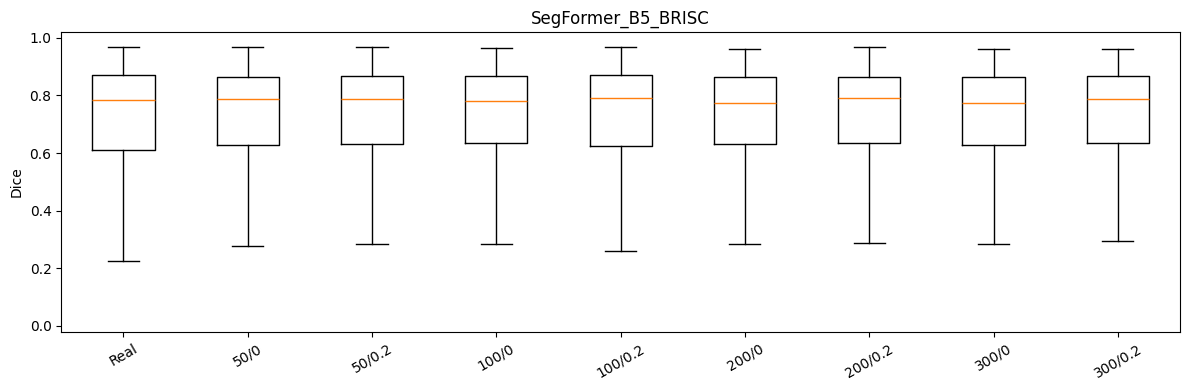

In [9]:
if RUN_DICE and not dice_individual.empty:
    # Media macro = media de los 9 Dice medios por condición (mismos pesos que en sintéticas).
    per_cond=dice_individual.groupby(["modelo","config","condition"],as_index=False).agg(
        n=("dice","size"),media=("dice","mean"),de=("dice","std"),mediana=("dice","median"))
    summary=dice_individual.groupby(["modelo","config"],as_index=False).agg(
        n=("dice","size"),media=("dice","mean"),de=("dice","std"),mediana=("dice","median"))
    macro=per_cond.groupby(["modelo","config"]).media.mean().rename("media_equilibrada_9_condiciones").reset_index()
    summary=summary.merge(macro,on=["modelo","config"],how="left")
    # Las sintéticas tienen exactamente 100 por condición; global==macro (hasta redondeo).
    syn_rows=summary[summary.config!="real"]
    assert np.allclose(syn_rows.media.to_numpy(),syn_rows.media_equilibrada_9_condiciones.to_numpy(),atol=1e-10)
    real_base=summary.loc[summary.config=="real",["modelo","media_equilibrada_9_condiciones"]].rename(
        columns={"media_equilibrada_9_condiciones":"referencia_real_macro"})
    summary=summary.merge(real_base,on="modelo",how="left")
    summary["brecha_macro_vs_real"]=summary.media_equilibrada_9_condiciones-summary.referencia_real_macro
    save_csv(summary,DIRS["04_dice"]/"dice_resumen_por_segmentador_y_config.csv")
    save_csv(per_cond,DIRS["04_dice"]/"dice_por_segmentador_config_condicion.csv")
    display(summary.round(4))
    print("Medias por condición (incluye referencia real)")
    display(per_cond.pivot_table(index=["modelo","condition"],columns="config",values="media").round(3))
    fig,axes=plt.subplots(len(PREDICTORS),1,figsize=(max(12,1.3*(N_CONFIGS+1)),4*len(PREDICTORS)),squeeze=False)
    for ax,(name,g) in zip(axes.ravel(),dice_individual.groupby("modelo",sort=False)):
        data=[g.loc[g.config==q,"dice"].to_numpy() for q in ["real"]+CONFIG_TAGS]
        ax.boxplot(data,tick_labels=["Real"]+[f"{s}/{eta:g}" for s,eta in CONFIGS],showfliers=False)
        ax.tick_params(axis="x",labelrotation=30)
        ax.set_ylim(-.02,1.02);ax.set_ylabel("Dice");ax.set_title(name)
    fig.tight_layout();fig.savefig(DIRS["04_dice"]/"boxplot_dice_por_segmentador.png",dpi=170)
    plt.show()

### Verificación visual de las segmentaciones

Se visualizan ejemplos reales y sintéticos junto con las segmentaciones obtenidas mediante los modelos externos.


[transformers] You passed `num_labels=2` which is incompatible to the `id2label` map of length `150`.


Loading weights:   0%|          | 0/1172 [00:00<?, ?it/s]

[transformers] SegformerForSemanticSegmentation LOAD REPORT from: nvidia/segformer-b5-finetuned-ade-640-640
Key                           | Status   |                                                                                                     
------------------------------+----------+-----------------------------------------------------------------------------------------------------
decode_head.classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([150, 768, 1, 1]) vs model:torch.Size([2, 768, 1, 1])
decode_head.classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([150]) vs model:torch.Size([2])                      

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


SegFormer_B5_BRISC cargado: 16 tensores; dispositivo: cuda


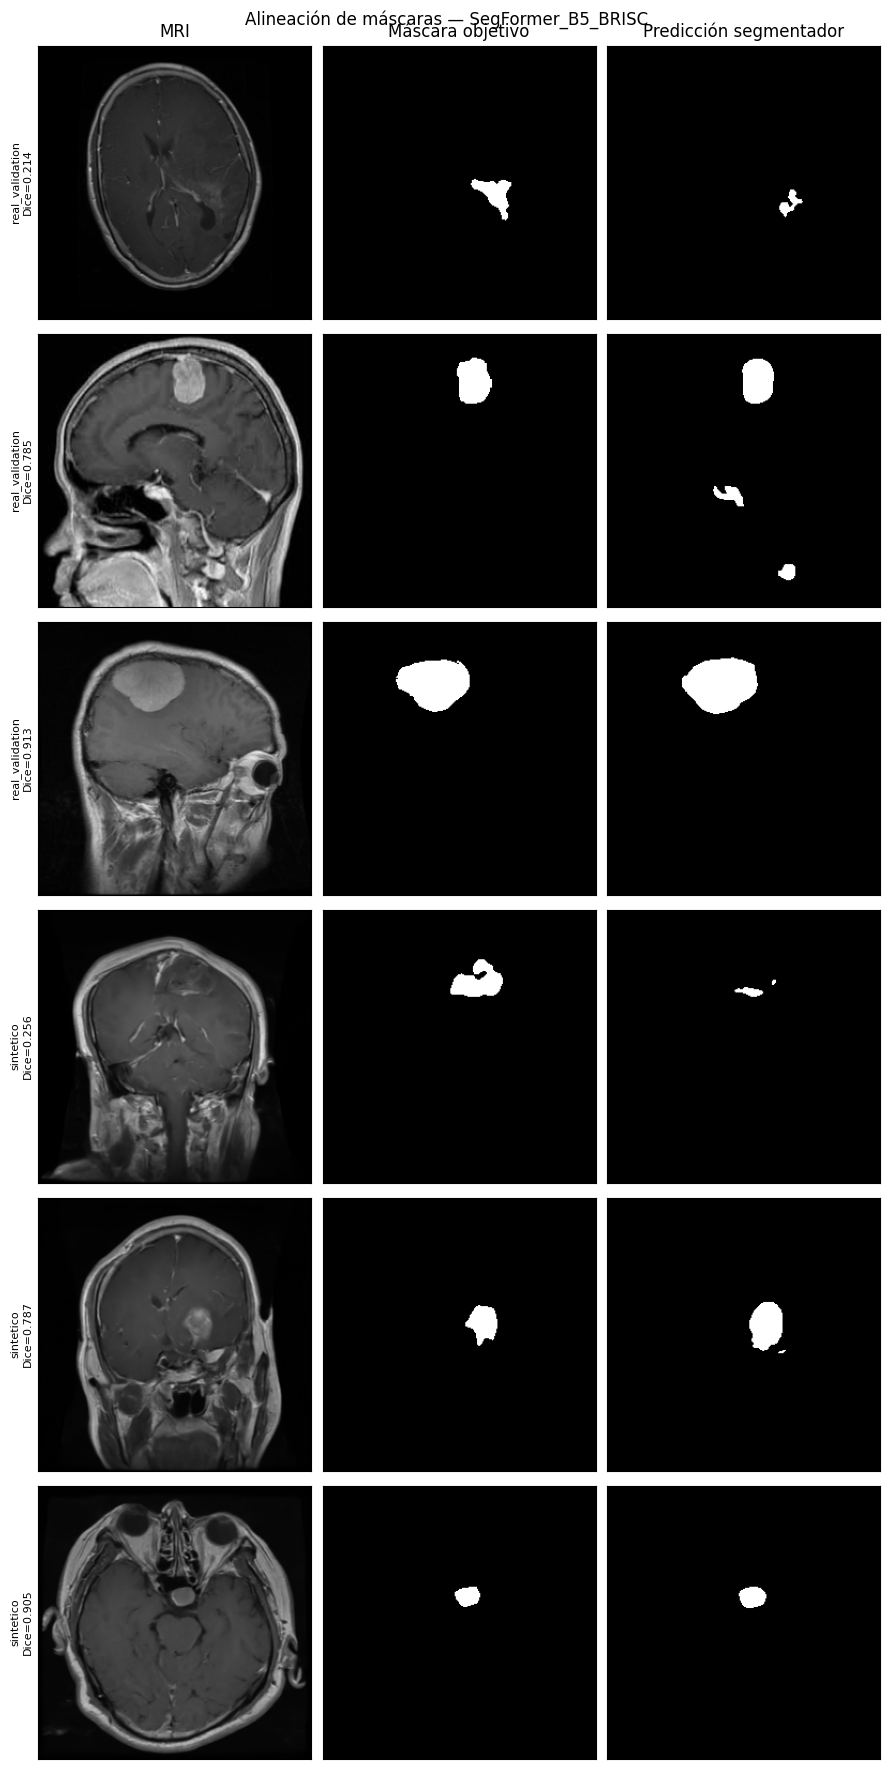

In [10]:
if RUN_DICE and not dice_individual.empty:
    for name in PREDICTORS:
        selected=[]
        for label in ["real_validation","sintetico"]:
            group=dice_individual.loc[(dice_individual.modelo==name)&(dice_individual.dataset==label)].sort_values("dice")
            if label=="sintetico":group=group.loc[group.config==CONFIG_TAGS[0]]
            if group.empty:continue
            for q in (.10,.50,.90):
                selected.append(group.iloc[min(len(group)-1,round((len(group)-1)*q))])
        if not selected:continue
        if name == "SegFormer_B5_BRISC":
            segformer_model, segformer_device = load_segformer()
        try:
            fig,axes=plt.subplots(len(selected),3,figsize=(9,3*len(selected)),squeeze=False)
            for rr,r in enumerate(selected):
                gray=read_gray(r.image_path)
                true=read_mask(r.mask_path)
                prob=np.asarray(PREDICTORS[name](gray),dtype=np.float32)
                predicted=prob>=SEGMENTATION_THRESHOLDS[name]
                assert prob.shape==gray.shape
                axes[rr,0].imshow(gray,cmap="gray",vmin=0,vmax=255)
                axes[rr,1].imshow(true,cmap="gray",vmin=0,vmax=1)
                axes[rr,2].imshow(predicted,cmap="gray",vmin=0,vmax=1)
                axes[rr,0].set_ylabel(f"{r.dataset}\nDice={r.dice:.3f}",fontsize=8)
                for cc in range(3):axes[rr,cc].set_xticks([]);axes[rr,cc].set_yticks([])
            for cc,title in enumerate(["MRI","Máscara objetivo","Predicción segmentador"]):
                axes[0,cc].set_title(title)
            fig.suptitle(f"Alineación de máscaras — {name}")
            fig.tight_layout()
            fig.savefig(DIRS["04_dice"]/f"panel_alineamiento_{name}.png",dpi=150)
            plt.show()
        finally:
            if name == "SegFormer_B5_BRISC":
                segformer_model = None
                segformer_device = None
                gc.collect()
                if torch.cuda.is_available(): torch.cuda.empty_cache()

## 8. Inspección visual comparativa

Se presentan imágenes generadas con distintas configuraciones a partir de las mismas máscaras y semillas.


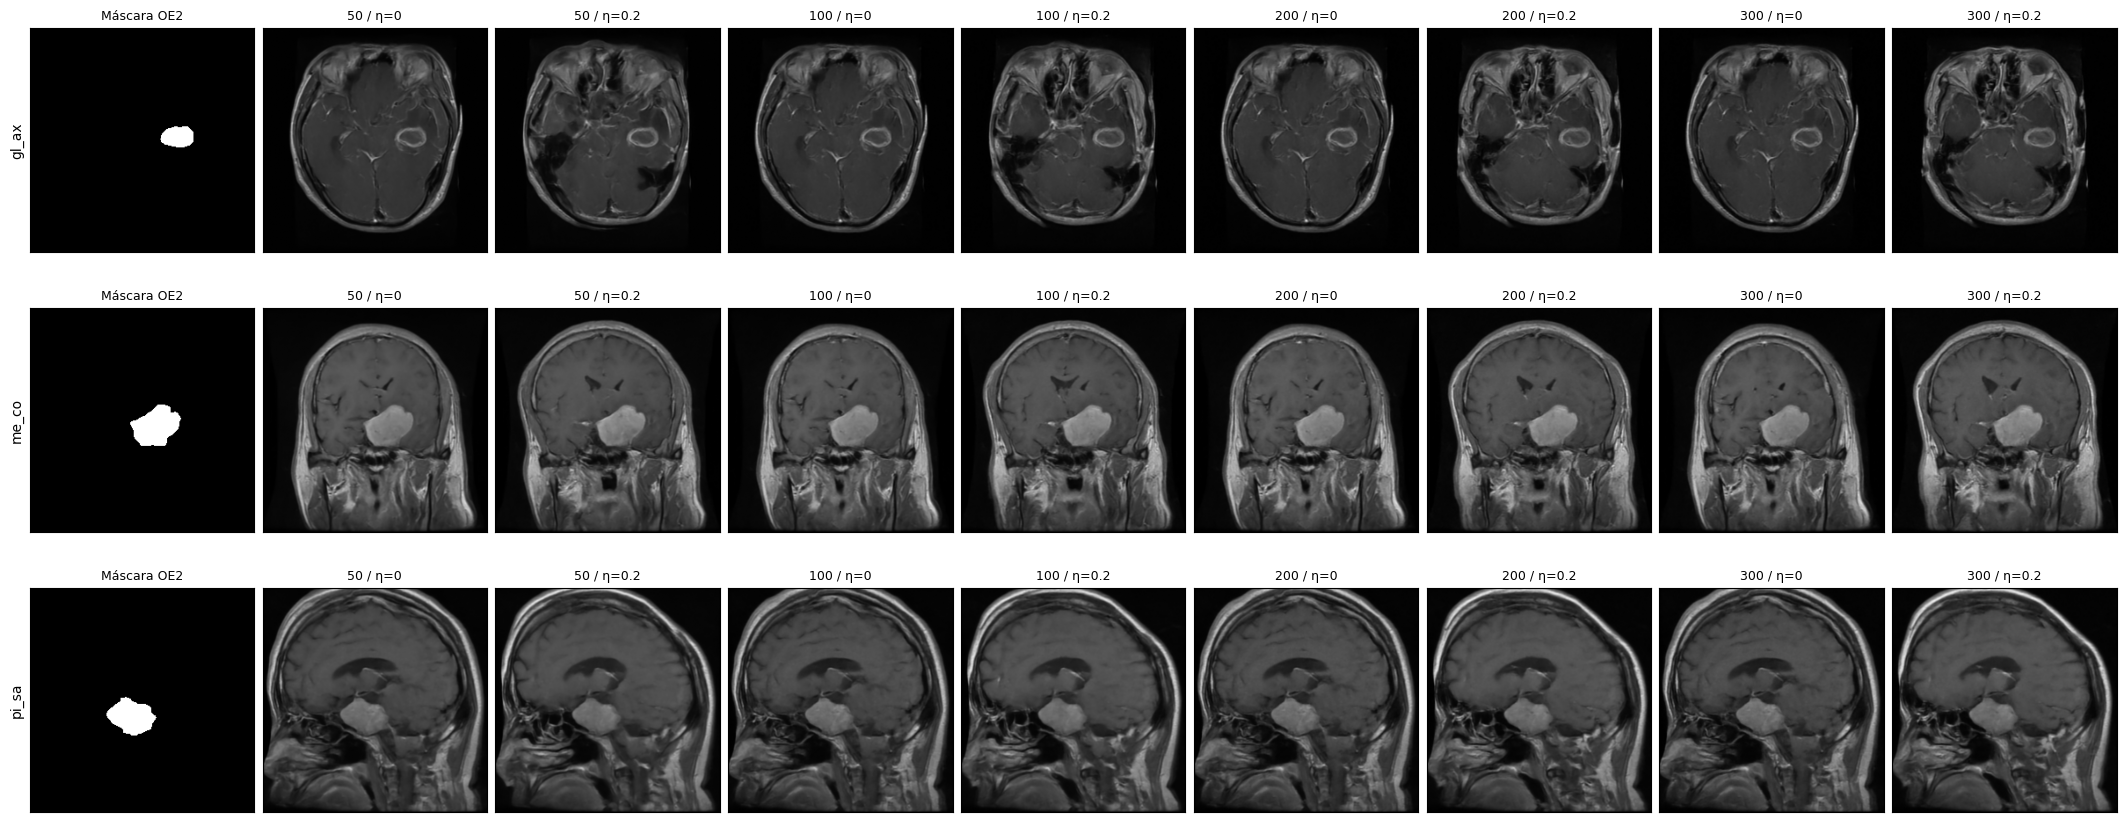

In [11]:
examples=[]
base=syn.loc[syn.config==CONFIG_TAGS[0]].sort_values("case_key")
for cond in ["gl_ax","me_co","pi_sa"]:
    group=base[base.condition==cond]
    if group.empty:raise RuntimeError(f"Sin ejemplo para {cond}")
    examples.append(str(group.iloc[len(group)//2].case_key))
N_PANEL_ROWS = len(examples)
N_PANEL_COLS = N_CONFIGS + 1  # máscara + una imagen por configuración
fig,axes=plt.subplots(
    N_PANEL_ROWS, N_PANEL_COLS,
    figsize=(max(17, 2.35*N_PANEL_COLS), 2.8*N_PANEL_ROWS),
    layout="constrained", squeeze=False,
)
for ri,key in enumerate(examples):
    sub=syn.loc[syn.case_key==key].set_index("config")
    axes[ri,0].imshow(read_mask(sub.iloc[0].mask_path),cmap="gray",vmin=0,vmax=1)
    axes[ri,0].set_ylabel(key.split("/")[0]);axes[ri,0].set_title("Máscara OE2",fontsize=9)
    for ci,tag in enumerate(CONFIG_TAGS,1):
        axes[ri,ci].imshow(read_gray(sub.loc[tag,"image_path"]),cmap="gray",vmin=0,vmax=255)
        axes[ri,ci].set_title(f"{CONFIGS[ci-1][0]} / η={CONFIGS[ci-1][1]:g}",fontsize=9)
    for ax in axes[ri]:ax.set_xticks([]);ax.set_yticks([])
fig.savefig(DIRS["05_comparacion"]/"panel_misma_mascara_todas_configuraciones.png",dpi=180)
plt.show()

## 9. Tabla comparativa de configuraciones

Se integran los indicadores disponibles para comparar las configuraciones DDIM y se registra el protocolo ejecutado.


In [ ]:
summary_final=pd.DataFrame({"config":CONFIG_TAGS,"pasos":[s for s,e in CONFIGS],
                            "eta":[e for s,e in CONFIGS]})
if RUN_QUALITY:
    summary_final=summary_final.merge(qc_overall[["config","alguna_alerta","alguna_alerta_pct",
        "AR_bajo","BE_alto"]],on="config",how="left")
if RUN_FID_VALIDATION and not fid_val_repeticiones.empty:
    piv=fid_val_resumen.pivot(index="config",columns="extractor",values="media").rename(
        columns={"InceptionV3":"FID_InceptionV3_medio","DINOv2_S":"FD_DINOv2_medio"})
    summary_final=summary_final.merge(piv.reset_index(),on="config",how="left")
    for ex in FID_EXTRACTORS:
        ordered=fid_val_resumen.loc[fid_val_resumen.extractor==ex].sort_values("media")
        summary_final[f"rango_{ex}"]=summary_final.config.map({v:i+1 for i,v in enumerate(ordered.config)})
if RUN_DICE and not dice_individual.empty:
    syn_dice=summary.loc[(summary.config!="real") & (summary.modelo==PRIMARY_DICE_OE3),
                          ["config","media_equilibrada_9_condiciones"]].rename(
        columns={"media_equilibrada_9_condiciones":f"Dice_macro_{PRIMARY_DICE_OE3}"})
    if len(syn_dice)!=N_CONFIGS or syn_dice.config.nunique()!=N_CONFIGS:
        raise RuntimeError("Faltan resultados SegFormer para alguna configuración DDIM")
    summary_final=summary_final.merge(syn_dice,on="config",how="left",validate="one_to_one")
save_csv(summary_final,DIRS["05_comparacion"]/"tabla_integrada_seleccion_ddim.csv")
display(summary_final.round(4))

if RUN_FID_VALIDATION and not fid_val_repeticiones.empty:
    for ex in FID_EXTRACTORS:
        ordered=fid_val_resumen[fid_val_resumen.extractor==ex].sort_values("media")
        print(ex,"— menor FID medio:",ordered.iloc[0].config,
              f"({ordered.iloc[0].media:.3f})")
print("\nNo se ha seleccionado automáticamente una configuración.")
print("La comparación integrada incluye controles de calidad, Dice y costo de muestreo.")

protocol={
    "design":"OE3 V3 seleccionar DDIM; validación reservada para selección, test_final no utilizado",
    "seed":SEED,"configs":CONFIG_TAGS,"n_configs":N_CONFIGS,"n_validation":len(real_val),"n_synthetic_per_config":EXPECTED_SYNTH_PER_CONFIG,
    "fid_extractors":["InceptionV3 pytorch-fid pool3 2048","DINOv2-small CLS 384"],
    "fid_repeats":N_FID_REPEATS,"fid_train_extra_repeats":N_FID_TRAIN_EXTRA_REPEATS,"fid_sampling":"stratified without replacement, same case IDs",
    "qc_bounds":"train AR unilateral P1 por plano; BE unilateral P99 por tumor-plano",
    "qc_BE_background":"exterior of largest connected component C15 of R15; brightness >=22",
    "qc_parameters": QC_PARAMETERS,
    "qc_outputs_directory": str(DIRS["01_controles"]),
    "dice_segmenters":list(PREDICTORS) if RUN_DICE else [],
    "dice_primary_oe3":PRIMARY_DICE_OE3 if RUN_DICE else None,
    "dice_complementary_oe4":[m for m in PREDICTORS if m!=PRIMARY_DICE_OE3] if RUN_DICE else [],
    "dice_no_bootstrap":True,"test_final_accessed":False,"extra_train_exploratory":bool(RUN_FID_TRAIN_EXTRA),
    "exploratory_train_fid_executed":bool(RUN_FID_TRAIN_EXTRA),
}
(DIRS["05_comparacion"]/"protocolo_ejecutado.json").write_text(
    json.dumps(protocol,ensure_ascii=False,indent=2),encoding="utf8")
